## Convolutional Neural Network



In this notebook you will learn to distinguish dogs from cats!

Data:
https://drive.google.com/drive/folders/1KpT0oBIb3aDaBtjf7Hs4WAUPoFEpbsYr?usp=sharing

Fill all the necessary gaps in cells (all of them are marked with "TO FILL") below and train neural networks for binary classification task.

## Task 1:

1. Build and fit CNN with 3 convolutional layers for binary classification
2. Evaluate accuracy on test data
3. Plot the graphs for Loss(number_of_epochs) and Accuracy(number_of_epochs)

First, let's load all the necessary functions:


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
import numpy as np

In [2]:
# from google.colab import drive
# drive.mount('/content/drive/')

In [3]:
# You should add shortcut to Cats_and_Dogs.zip into your own google drive or just copy it
# After that copy archive with images to local colab folder - /content/ - by running this cell
# Reading files directly from '/content/drive/' will take much longer time for training!
# WARNING: /content/ will be cleaned after finishing current colab session

#!cp "/content/drive/My Drive/Cats_and_Dogs.zip" "/content/Cats_and_Dogs.zip"

In [4]:
# this code is necessary for unzipping and organizing folders structure in /content/

import zipfile
import os

# archive = '/content/Cats_and_Dogs.zip'
# destination = '/content/Cats_and_Dogs'
#
# with zipfile.ZipFile(archive, 'r') as zf:
#     for member in zf.namelist():
#
#         # Find the position of Cats_and_Dogs in the archive path
#         parts = member.split('/')
#         if 'Cats_and_Dogs' not in parts:
#             continue
#
#         idx = parts.index('Cats_and_Dogs')
#         relative_path = os.path.join(*parts[idx+1:])
#
#         if not relative_path:
#             continue
#
#         target = os.path.join(destination, relative_path)
#
#         if member.endswith('/'):
#             os.makedirs(target, exist_ok=True)
#         else:
#             os.makedirs(os.path.dirname(target), exist_ok=True)
#             with zf.open(member) as src, open(target, 'wb') as dst:
#                 dst.write(src.read())
#
# print("Extraction completed!")

# Local server configuration (uncomment the block below if you work with colab)
archive = "Cats_and_Dogs.zip"
destination = os.path.expanduser("~/PycharmProjects/MLT/Lab4/Cats_and_Dogs")

with zipfile.ZipFile(archive, "r") as zf:
    for member in zf.namelist():
        parts = member.split("/")
        if "Cats_and_Dogs" not in parts:
            continue
        idx = parts.index("Cats_and_Dogs")
        relative_path = os.path.join(*parts[idx + 1 :])
        if not relative_path:
            continue
        target = os.path.join(destination, relative_path)
        if member.endswith("/"):
            os.makedirs(target, exist_ok=True)
        else:
            os.makedirs(os.path.dirname(target), exist_ok=True)
            with zf.open(member) as src, open(target, "wb") as dst:
                dst.write(src.read())

print("Extraction completed!")




Extraction completed!


In [5]:
# result should be 'test  train  val'
# !ls /content/Cats_and_Dogs

!ls /home/nathaliemac/PycharmProjects/MLT/Lab4/Cats_and_Dogs

test  train  val


In [6]:
# TO FILL

# Initialize the folders with train, test and validation datasets
# Paths are configured here for '/content/Cats_and_Dogs/'

#Orig paths
# train = '/content/Cats_and_Dogs/train'
# val =   '/content/Cats_and_Dogs/val'
# test =  '/content/Cats_and_Dogs/test'

# Server paths: 
train = "/home/nathaliemac/PycharmProjects/MLT/Lab4/Cats_and_Dogs/train"
val = "/home/nathaliemac/PycharmProjects/MLT/Lab4/Cats_and_Dogs/val"
test = "/home/nathaliemac/PycharmProjects/MLT/Lab4/Cats_and_Dogs/test"

# The shape of the RGB image
img_width, img_height, channels = 150, 150, 3 # you can try different scales

# input shape for PyTorch (channels first)
input_shape = (3, img_height, img_width)  # PyTorch uses (N, C, H, W) format for input data - (batch_size, channels, height, width)

# Set device (GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# minibatch size. You can try 64 at first, and compare results with 16, 32, 128
batch_size = 64


Using device: cuda


In [7]:
#!ls /content/Cats_and_Dogs

!ls Cats_and_Dogs

test  train  val


## Prepare the data.

You don't have to manually change the shapes of 25000 images and convert them into the necessary format for PyTorch (3, img_width, img_height).

We will use PyTorch's built-in data loading utilities: _transforms_ and _DataLoader_.

It performs scaling, resizes selected images and prepares batches (mini-samples) to train the model.

In [8]:
# Define transforms for data preprocessing
# PyTorch transforms: resize, convert to tensor (scales to [0,1]), and normalize
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),  # Converts to tensor and scales to [0, 1]
    ]),
    'val': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
    ]),
    'test': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
    ])
}

# Create datasets using ImageFolder (expects subdirectories for each class)
train_dataset = datasets.ImageFolder(train, transform=data_transforms['train'])
val_dataset = datasets.ImageFolder(val, transform=data_transforms['val'])
test_dataset = datasets.ImageFolder(test, transform=data_transforms['test'])

# Create data loaders
# Note: num_workers=2 for Colab (uses multiprocessing for faster data loading)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2,    pin_memory=True,
    persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2,    pin_memory=True,
    persistent_workers=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2,    pin_memory=True,
    persistent_workers=True)

Set the network architecture by sequentially adding layers to it:
1. A convolutional layer with 16 neurons (# output channels), filter size 3x3. Activation function - 'relu'
2. MaxPooling layer with filter size 2x2.
3. A convolutional layer with 32 neurons (# output channels), filter size 3x3. Activation function - 'relu'
4. MaxPooling layer with filter size 2x2.
5. A convolutional layer with 64 neurons (# output channels), filter size 3x3. Activation function - 'relu'
6. MaxPooling layer with filter size 2x2.
7. Flatten operation, which makes a one-dimensional vector of the resulting feature maps.
8. A fully connected layer with 64 neurons. Activation function - 'relu'
9. Dropout(0.5) which excludes neurons with a 50% probability to avoid overfitting.
10. A fully connected layer with 1 neuron. Activation function - 'sigmoid', because binary classification model.

Add to the model all the missing layers, by analogy with the already specified.
PyTorch documentation: https://pytorch.org/docs/stable/nn.html

In [9]:
# TO FILL

# Define CNN model as a PyTorch class
class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()

        # 1: Convolutional layer with 16 output channels, 3x3 kernel
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()

        # 2: MaxPooling layer with 2x2 kernel
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # 3: Convolutional layer with 32 output channels
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()

        # 4: Pooling
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # 5: Convolutional (64 channels)
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.relu3 = nn.ReLU()

        # 6: Pooling
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        # 7: Flatten (handled in forward pass)
        # After 3 pooling layers: 150 -> 75 -> 37 -> 18
        # 8: Dense (Fully Connected) with 64 neurons
        self.fc1 = nn.Linear(64 * 18 * 18, 64)
        self.relu4 = nn.ReLU()

        # 9: Dropout(0.5)
        self.dropout = nn.Dropout(0.5)

        # 10: Dense with 1 neuron (no sigmoid if using BCEWithLogitsLoss)
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x):
        # Forward pass through the network
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool1(x)

        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)

        x = self.conv3(x)
        x = self.relu3(x)
        x = self.pool3(x)

        # Flatten: convert (batch, channels, h, w) to (batch, channels*h*w)
        x = x.view(x.size(0), -1)

        x = self.fc1(x)
        x = self.relu4(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x

# Instantiate the model and move to device
model = CNNModel().to(device)
print(model)


CNNModel(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=20736, out_features=64, bias=True)
  (relu4): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=64, out_features=1, bias=True)
)


In [10]:
# Define loss function and optimizer
# Binary Cross Entropy with Logits (combines Sigmoid and BCE for better numerical stability)
# Note: If using BCEWithLogitsLoss, remove sigmoid from model's last layer
criterion = nn.BCEWithLogitsLoss()
# Alternatively: use nn.BCELoss() if you keep sigmoid in the model

optimizer = optim.Adam(model.parameters(), lr=0.001)

In [11]:
# uncomment if you want to use previously calculated weights from "models/*"

# import json

# with open("history/history_cnn.json") as f:
#     history_cnn = json.load(f)

# train_losses = history_cnn["train_losses"]
# train_accuracies = history_cnn["train_accuracies"]
# val_losses = history_cnn["val_losses"]
# val_accuracies = history_cnn["val_accuracies"]

# model.load_state_dict(torch.load('models/cnn_part1.pt', map_location=device))

In [12]:

# Training loop for PyTorch

# you can try different number of epochs: 10, 15, 20; check the learning curves, loss and accuracy;
num_epochs =  10

# Lists to store training history
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

# Main training loop
for epoch in range(num_epochs):
    # Training phase
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)  # Reshape for binary classification

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item()
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # Validation phase
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = 100 * val_correct / val_total
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f'Epoch [{epoch+1}/{num_epochs}], '
          f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')

Epoch [1/10], Train Loss: 0.6733, Train Acc: 56.80%, Val Loss: 0.6202, Val Acc: 64.18%
Epoch [2/10], Train Loss: 0.5792, Train Acc: 69.46%, Val Loss: 0.5218, Val Acc: 74.70%
Epoch [3/10], Train Loss: 0.5100, Train Acc: 75.11%, Val Loss: 0.4806, Val Acc: 77.35%
Epoch [4/10], Train Loss: 0.4477, Train Acc: 79.20%, Val Loss: 0.4462, Val Acc: 78.31%
Epoch [5/10], Train Loss: 0.4108, Train Acc: 81.55%, Val Loss: 0.4447, Val Acc: 79.56%
Epoch [6/10], Train Loss: 0.3680, Train Acc: 83.50%, Val Loss: 0.4201, Val Acc: 81.37%
Epoch [7/10], Train Loss: 0.3334, Train Acc: 85.26%, Val Loss: 0.4075, Val Acc: 81.45%
Epoch [8/10], Train Loss: 0.2933, Train Acc: 87.72%, Val Loss: 0.4404, Val Acc: 81.81%
Epoch [9/10], Train Loss: 0.2589, Train Acc: 89.14%, Val Loss: 0.4357, Val Acc: 81.33%
Epoch [10/10], Train Loss: 0.2235, Train Acc: 90.72%, Val Loss: 0.4298, Val Acc: 82.73%


In [13]:
# Evaluate on test data
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)

        outputs = model(images)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_accuracy = 100 * test_correct / test_total
print(f"Accuracy on test data: {test_accuracy:.2f}%")

Accuracy on test data: 82.08%


In [15]:
# save model and weights
import json

torch.save(model.state_dict(), 'models/cnn_part1.pt')
history_cnn = {
    "train_losses": train_losses,
    "train_accuracies": train_accuracies,
    "val_losses": val_losses,
    "val_accuracies": val_accuracies,
    "test_accuracy": test_accuracy,
}

with open("history/history_cnn.json", "w") as f:
    json.dump(history_cnn, f)

Plot the graphs:

- Loss(Number of epochs)

- Accuracy(Number of epochs)

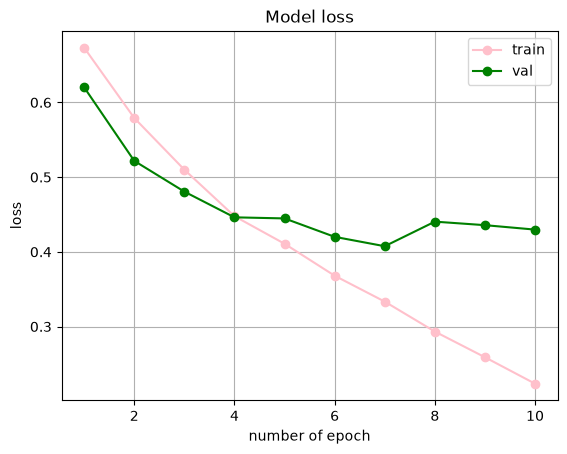

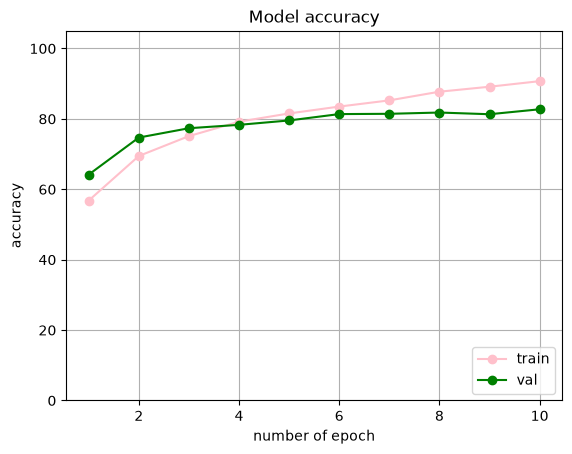

In [16]:
# TO FILL

import matplotlib.pyplot as plt

# Plot Loss
plt.figure()
plt.title("Model loss")
plt.grid(True)
plt.plot(range(1, len(train_losses) + 1), train_losses, 'pink', marker='o', label='train')
plt.plot(range(1, len(train_losses) + 1), val_losses, 'green', marker='o', label='val')
#plt.ylim((0.0, 1.05))
plt.legend(loc='upper right')
plt.xlabel("number of epoch")
plt.ylabel("loss")
plt.show()

# Plot Accuracy
plt.figure()
plt.title("Model accuracy")
plt.grid(True)
plt.plot(range(1, len(train_losses) + 1), train_accuracies, 'pink', marker='o', label='train')
plt.plot(range(1, len(train_losses) + 1), val_accuracies, 'green', marker='o', label='val')
plt.ylim((0.0, 105))
plt.legend(loc='lower right')
plt.xlabel("number of epoch")
plt.ylabel("accuracy")
plt.show()

**Conclusions**:
Training loss decreased  from about 0.67 to 0.22, and training accuracy rose to about 91%. Validation loss stopped improving after epoch №7 and stayed around 0.43, while validation accuracy raised to 83%. The increasing gap between the training and validation curves shows that the model starts to overfit after approximately epoch №7, so further training does not improve generalization. The final accuracy on the test set is 82.08%.

Let's try to improve the quality of recognition, using the method of transfer learning.

We will use weights of deep neural networks already trained on large dataset such as  ImageNet, and provide fine tuning of several additional dense layers on new data relevant to the current classification task. The more new images will differ from those on which the network has been trained, the more layers will need to be “retrained” in order to get good classification accuracy. The intuition here is that the model has already learned how to highlight the necessary features on the images in the large dataset, it only needs to be “tweaked” for a specific task.

## Task 2

1. Build and fit Transfer Learning model using pre-trained VGG16-model weights from torchvision.models.
2. Do the same with **another available pre-trained deep learning model** from torchvision.models https://pytorch.org/vision/stable/models.html.
3. Evaluate accuracy on test data for p.1 and p.2
4. Plot the graphs for Loss(number_of_epochs) and Accuracy(number_of_epochs)
5. Check the performance of your model with the custom image of cat or dog (so the model will tell which class this image belongs to). Develop the function for the inference of the best algorithm.

In [17]:
# First, download the weights of the VGG16 network trained on the ImageNet dataset:
# PyTorch will automatically download the weights when you first run this

vgg16_net = models.vgg16(weights=models.VGG16_Weights.DEFAULT)  # Load pre-trained VGG16
# Remove the classifier (fully connected layers) - we take only the "convolution" part
vgg16_net = vgg16_net.features  # Extract only convolutional features

# Freeze the weights - we do NOT want to retrain the VGG16 layers
# Weights VGG16 in the process of learning will remain unchanged!
for param in vgg16_net.parameters():
    param.requires_grad = False

print(vgg16_net)  # pay attention to the architecture

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (17): Conv2d(256, 512, kernel_si

We construct our model of "transfer learning" by adding two fully connected layers to VGG16

In [18]:
# Build transfer learning model by adding fully connected layers to VGG16

class VGG16TransferModel(nn.Module):
    def __init__(self, vgg16_features):
        super(VGG16TransferModel, self).__init__()
        self.features = vgg16_features  # Pre-trained VGG16 features

        # Adaptive pooling to handle feature input sizes
        # That operation shrinks the feature map size to 7x7
        self.avgpool = nn.AdaptiveAvgPool2d((7, 7))

        # Flattening (done in forward)
        # Dense fully connected layer with 256 neurons
        self.fc1 = nn.Linear(512 * 7 * 7, 256)  # VGG16 outputs 512 channels
        self.relu = nn.ReLU()

        # Dropout
        self.dropout = nn.Dropout(0.5)

        # Dense layer with 1 neuron (no sigmoid if using BCEWithLogitsLoss)
        self.fc2 = nn.Linear(256, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)  # Flatten

        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x

model = VGG16TransferModel(vgg16_net).to(device)
print(model)

VGG16TransferModel(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, paddin

In [19]:
# Define loss and optimizer for transfer learning model
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-5)  # Lower learning rate 1e-5 for fine-tuning

In [20]:
# uncomment if you want to use previously calculated weights from "models/*"

# import json

# with open("history/history_vgg16.json") as f:
#     history_cnn = json.load(f)

# train_losses_transfer = history_cnn["train_losses_transfer"]
# train_accuracies_transfer = history_cnn["train_accuracies_transfer"]
# val_losses_transfer = history_cnn["val_losses_transfer"]
# val_accuracies_transfer = history_cnn["val_accuracies_transfer"]

# model.load_state_dict(torch.load('models/cnn_part2_vgg16.pt', map_location=device))

In [21]:
# TO FILL

# Training loop for transfer learning model

num_epochs_transfer = 5

# Lists to store training history
train_losses_transfer = []
train_accuracies_transfer = []
val_losses_transfer = []
val_accuracies_transfer = []

for epoch in range(num_epochs_transfer):
 # Training phase
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)  # Reshape for binary classification

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item()
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total
    train_losses_transfer.append(train_loss)
    train_accuracies_transfer.append(train_acc)

    # Validation phase
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = 100 * val_correct / val_total
    val_losses_transfer.append(val_loss)
    val_accuracies_transfer.append(val_acc)

    print(f'Epoch [{epoch+1}/{num_epochs_transfer}], '
          f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')


Epoch [1/5], Train Loss: 0.1904, Train Acc: 92.67%, Val Loss: 0.1285, Val Acc: 94.90%
Epoch [2/5], Train Loss: 0.1220, Train Acc: 95.28%, Val Loss: 0.1127, Val Acc: 95.50%
Epoch [3/5], Train Loss: 0.1073, Train Acc: 95.83%, Val Loss: 0.1065, Val Acc: 96.10%
Epoch [4/5], Train Loss: 0.0970, Train Acc: 96.31%, Val Loss: 0.1039, Val Acc: 95.98%
Epoch [5/5], Train Loss: 0.0881, Train Acc: 96.72%, Val Loss: 0.1024, Val Acc: 95.98%


In [22]:
# Evaluate transfer learning model on test data
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)

        outputs = model(images)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_accuracy = 100 * test_correct / test_total
print(f"Accuracy on test data: {test_accuracy:.2f}%")

Accuracy on test data: 94.80%


In [23]:
# save model and weights

torch.save(model.state_dict(), 'models/cnn_part2_vgg16.pt')
history_cnn = {
    "train_losses_transfer": train_losses_transfer,
    "train_accuracies_transfer": train_accuracies_transfer,
    "val_losses_transfer": val_losses_transfer,
    "val_accuracies_transfer": val_accuracies_transfer,
    "test_accuracy": test_accuracy,
}

with open("history/history_vgg16.json", "w") as f:
    json.dump(history_cnn, f)

Plot the training history for transfer learning:

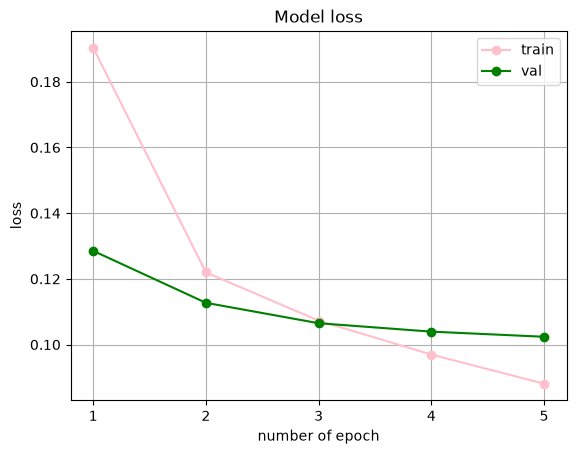

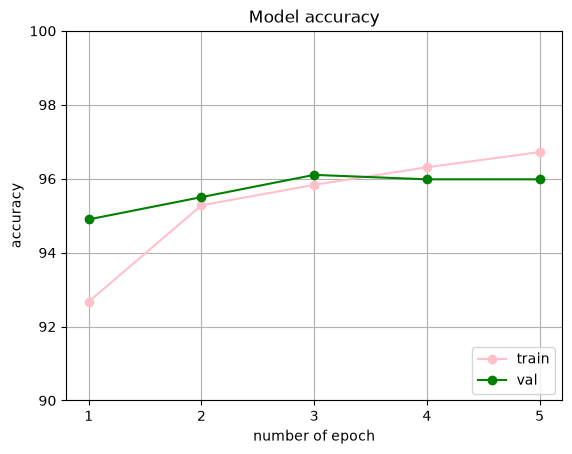

In [24]:
# TO FILL

# Plot learning curves for transfer learning model

# Plot Loss
plt.figure()

plt.title("Model loss")
plt.grid(True)
plt.xticks(range(1, len(train_losses_transfer) + 1))
plt.plot(range(1, len(train_losses_transfer) + 1), train_losses_transfer, 'pink', marker='o', label='train')
plt.plot(range(1, len(train_losses_transfer) + 1), val_losses_transfer, 'green', marker='o', label='val')
#plt.ylim((0.0, 1.05))
plt.legend(loc='upper right')
plt.xlabel("number of epoch")
plt.ylabel("loss")
plt.show()

# Plot Accuracy
plt.figure()
plt.title("Model accuracy")
plt.grid(True)
plt.xticks(range(1, len(train_losses_transfer) + 1))
plt.plot(range(1, len(train_losses_transfer) + 1), train_accuracies_transfer, 'pink', marker='o', label='train')
plt.plot(range(1, len(train_losses_transfer) + 1), val_accuracies_transfer, 'green', marker='o', label='val')
plt.ylim((90.0, 100.0))
plt.legend(loc='lower right')
plt.xlabel("number of epoch")
plt.ylabel("accuracy")
plt.show()

**Conclusions:**
Training loss decreased from about 0.19 to 0.09, and training accuracy rose to about 97%. Validation loss decreased from from 0.13 to 0.10, validation accuracy increased from 95% to 96%. Validation metrics increase alongside with train. As there is no signs of overfitting and the gap between training and validation accuracy stays small, we can assume that the model generalizes well (test accuracy 95%)

## Another Transfer Learning model (on your choice from https://pytorch.org/vision/stable/models.html.)

MobileNetV2 was chosen

In [25]:
# TO FILL
# Repeat Transfer learning with another pre-trained weights

def build_mobilenet():
    mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    for param in mobilenet.parameters():
        param.requires_grad = False
    mobilenet.classifier[1] = nn.Linear(1280, 1)
    model_mobilenet = mobilenet.to(device)
    return model_mobilenet
    

In [26]:
# Training loop for MobileNetV2
def evaluate(model, loader, criterion):
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = 100 * val_correct / val_total
    return val_loss, val_acc

def train_model(model, optimizer, criterion, num_epochs):
    # Lists to store training history
    train_losses_mobilenet = []
    train_accuracies_mobilenet = []
    val_losses_mobilenet = []
    val_accuracies_mobilenet = []
    
    for epoch in range(num_epochs):
         # Training phase
        model.train()
    
        running_loss = 0.0
        correct = 0
        total = 0
    
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)  # Reshape for binary classification
    
            # Zero the parameter gradients
            optimizer.zero_grad()
    
            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)
    
            # Backward pass and optimize
            loss.backward()
            optimizer.step()
    
            # Statistics
            running_loss += loss.item()
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    
        train_loss = running_loss / len(train_loader)
        train_acc = 100 * correct / total
        train_losses_mobilenet.append(train_loss)
        train_accuracies_mobilenet.append(train_acc)
    
        # Validation phase
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        val_losses_mobilenet.append(val_loss)
        val_accuracies_mobilenet.append(val_acc)
        
        print(f'Epoch [{epoch+1}/{num_epochs}], '
              f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
              f'Val Loss: {val_losses_mobilenet[-1]:.4f}, Val Acc: {val_accuracies_mobilenet[-1]:.2f}%')
    return (train_losses_mobilenet, train_accuracies_mobilenet, val_losses_mobilenet, val_accuracies_mobilenet)

In [27]:
# Evaluate transfer learning model on test data 
import os

def run_experiment(lr, num_epochs=5, recalculate = True):
    model_file_name = f"models/cnn_part2_mobilenet_{lr}.pt"
    history_json_name = f"history/history_mobilenet_{lr}.json"

    if recalculate:
        model = build_mobilenet()
        optimizer = optim.Adam(model.classifier.parameters(), lr=lr)
        train_losses, train_accs, val_losses, val_accs = train_model(model, optimizer, nn.BCEWithLogitsLoss(), num_epochs)
        
        # test
        model.eval()
        test_correct = 0
        test_total = 0
        
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                labels = labels.float().unsqueeze(1)
        
                outputs = model(images)
                predicted = (torch.sigmoid(outputs) > 0.5).float()
                test_total += labels.size(0)
                test_correct += (predicted == labels).sum().item()
        
        test_accuracy = 100 * test_correct / test_total
        print(f"Accuracy on test data: {test_accuracy:.2f}%")
        
        # save model and weights
        torch.save(model.state_dict(), model_file_name)
        history_cnn = {
            "train_losses_mobilenet": train_losses,
            "train_accuracies_mobilenet": train_accs,
            "val_losses_mobilenet": val_losses,
            "val_accuracies_mobilenet": val_accs,
            "test_accuracy": test_accuracy,
        }
    
        with open(history_json_name, "w") as f:
            json.dump(history_cnn, f)
    else:
        if not os.path.exists(history_json_name):
            raise FileNotFoundError(f"History file not found: {history_json_name}")
        if not os.path.exists(model_file_name):
            raise FileNotFoundError(f"Model file not found: {model_file_name}")

        with open(history_json_name, "r") as f:
            history_cnn = json.load(f)
        train_losses = history_cnn["train_losses_mobilenet"]
        train_accs = history_cnn["train_accuracies_mobilenet"]
        val_losses = history_cnn["val_losses_mobilenet"]
        val_accs = history_cnn["val_accuracies_mobilenet"]

        model = build_mobilenet().to(device)
        model.load_state_dict(torch.load(model_file_name, map_location=device))
        model.eval()
        test_accuracy = history_cnn["test_accuracy"]

        
    results_dict = {"Model": "MobileNetV2", "lr": f"{lr:e}", "Epochs": num_epochs,
     "Train loss": train_losses[-1], "Train acc": train_accs[-1],
     "Val loss": val_losses[-1], "Val acc": val_accs[-1],
     "Test acc": test_accuracy}
    
    return results_dict, model_file_name, history_json_name

In [28]:
# Plot learning curves for MobileNetV2
def draw_plots(train_losses_mobilenet, train_accuracies_mobilenet, val_losses_mobilenet,val_accuracies_mobilenet):
    num_epochs_mobilenet = len(train_losses_mobilenet)
    # Plot Loss
    plt.figure()
    plt.title("Model loss")
    plt.grid(True)
    plt.xticks(range(1, num_epochs_mobilenet+1))
    plt.plot(range(1, num_epochs_mobilenet+1), train_losses_mobilenet, 'pink', marker='o', label='train')
    plt.plot(range(1, num_epochs_mobilenet+1), val_losses_mobilenet, 'green', marker='o', label='val')
    #plt.ylim((0.0, 1.05))
    plt.legend(loc='right')
    plt.xlabel("number of epoch")
    plt.ylabel("loss")
    plt.show()
    
    # Plot Accuracy
    plt.figure()
    plt.title("Model accuracy")
    plt.grid(True)
    plt.xticks(range(1, num_epochs_mobilenet+1))
    plt.plot(range(1, num_epochs_mobilenet+1), train_accuracies_mobilenet, 'pink', marker='o', label='train')
    plt.plot(range(1, num_epochs_mobilenet+1), val_accuracies_mobilenet, 'green', marker='o', label='val')
    plt.ylim((0.0, 100.0))
    plt.legend(loc='lower right')
    plt.xlabel("number of epoch")
    plt.ylabel("accuracy")
    plt.show()

Epoch [1/5], Train Loss: 0.6653, Train Acc: 61.73%, Val Loss: 0.6347, Val Acc: 72.69%
Epoch [2/5], Train Loss: 0.6118, Train Acc: 75.90%, Val Loss: 0.5841, Val Acc: 82.77%
Epoch [3/5], Train Loss: 0.5670, Train Acc: 82.17%, Val Loss: 0.5395, Val Acc: 86.71%
Epoch [4/5], Train Loss: 0.5276, Train Acc: 85.07%, Val Loss: 0.5036, Val Acc: 88.07%
Epoch [5/5], Train Loss: 0.4950, Train Acc: 86.69%, Val Loss: 0.4731, Val Acc: 89.48%
Accuracy on test data: 89.12%


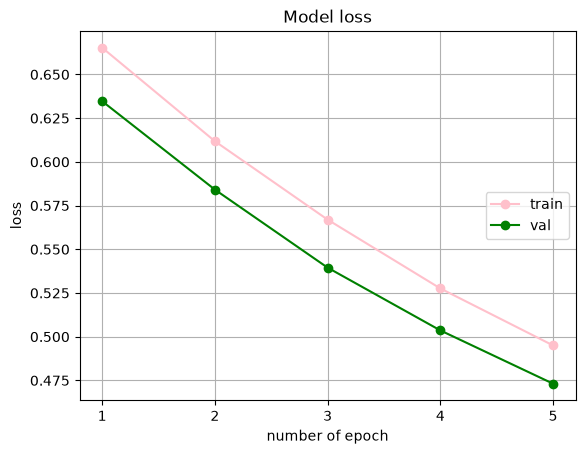

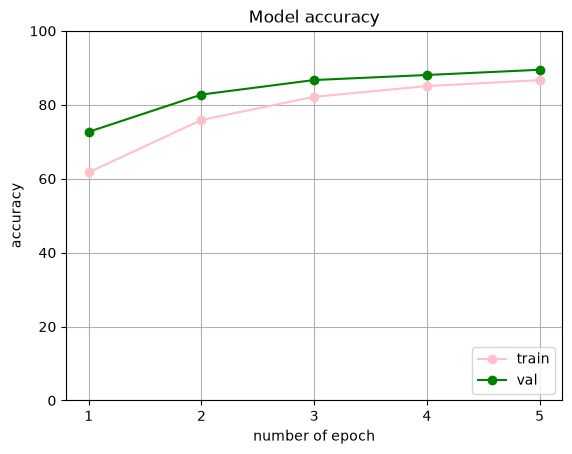

In [29]:
num_epochs = 5
learning_rate = 1e-5

# if u wanna download pretrained weigths from file
#recalculate = False

results_dict_5, model_file_name_5, history_json_name_5 = run_experiment(learning_rate, num_epochs, recalculate=True)

with open(history_json_name_5) as f:
    history_cnn = json.load(f)

train_losses = history_cnn["train_losses_mobilenet"]
train_accuracies = history_cnn["train_accuracies_mobilenet"]
val_losses = history_cnn["val_losses_mobilenet"]
val_accuracies = history_cnn["val_accuracies_mobilenet"]

draw_plots(train_losses, train_accuracies, val_losses,val_accuracies)

Epoch [1/10], Train Loss: 0.2530, Train Acc: 91.00%, Val Loss: 0.1560, Val Acc: 94.78%
Epoch [2/10], Train Loss: 0.1634, Train Acc: 93.72%, Val Loss: 0.1330, Val Acc: 94.94%
Epoch [3/10], Train Loss: 0.1491, Train Acc: 94.26%, Val Loss: 0.1335, Val Acc: 95.22%
Epoch [4/10], Train Loss: 0.1423, Train Acc: 94.36%, Val Loss: 0.1211, Val Acc: 95.30%
Epoch [5/10], Train Loss: 0.1368, Train Acc: 94.56%, Val Loss: 0.1167, Val Acc: 95.18%
Epoch [6/10], Train Loss: 0.1342, Train Acc: 94.58%, Val Loss: 0.1176, Val Acc: 95.14%
Epoch [7/10], Train Loss: 0.1324, Train Acc: 94.68%, Val Loss: 0.1115, Val Acc: 95.54%
Epoch [8/10], Train Loss: 0.1301, Train Acc: 94.69%, Val Loss: 0.1162, Val Acc: 95.54%
Epoch [9/10], Train Loss: 0.1285, Train Acc: 94.84%, Val Loss: 0.1116, Val Acc: 95.38%
Epoch [10/10], Train Loss: 0.1303, Train Acc: 94.83%, Val Loss: 0.1137, Val Acc: 95.22%
Accuracy on test data: 95.68%


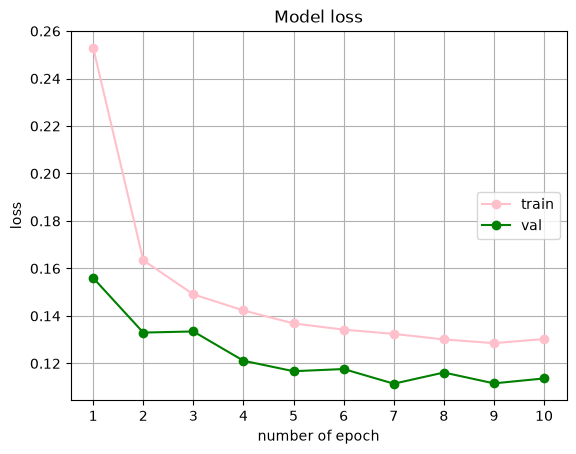

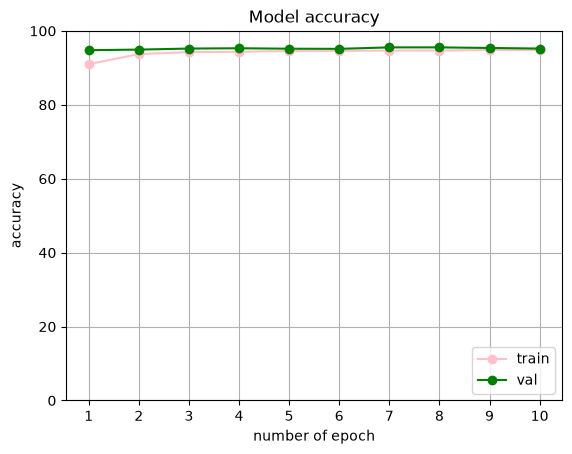

In [30]:
num_epochs = 10
learning_rate = 1e-3
results_dict_3, model_file_name_3, history_json_name_3 = run_experiment(learning_rate, num_epochs, recalculate=True)

with open(history_json_name_3) as f:
    history_cnn = json.load(f)

train_losses = history_cnn["train_losses_mobilenet"]
train_accuracies = history_cnn["train_accuracies_mobilenet"]
val_losses = history_cnn["val_losses_mobilenet"]
val_accuracies = history_cnn["val_accuracies_mobilenet"]

draw_plots(train_losses, train_accuracies, val_losses,val_accuracies)

###### **Conclusions:**
For learning rate=1e-5, 5 epochs:
Training loss decreased from about 0.67 to 0.50, and training accuracy rose to about 87%. Validation loss decreased from 0.63 to 0.47, validation accuracy increased from 73% to 89%. 
Loss still hasn't reached the plateau, so we can say model is not still converged, but as there is no signs of overfitting and the gap between training and validation accuracy stays small, we can assume that the model generalizes well (test accuracy 89%) at this stage.

For learning rate=1e-3, 10 epochs:
Training loss decreased from about 0.25 to 0.13, and training accuracy rose to about 95%. Validation loss decreased from 0.16 to 0.11, validation accuracy increased from 94.8% to 95%. 
Training loss has reached the plateau, so we can say model is well-trained, Moreover, the model generalizes well (test accuracy 96%), and there is no signs of overfitting.

## Comparison of thee models:

In [31]:
import pandas as pd

h_cnn = json.load(open("history/history_cnn.json"))
h_vgg16 = json.load(open("history/history_vgg16.json"))
h_mobilenet = json.load(open(history_json_name_3))

results = pd.DataFrame([
    {"Model": "CNN from scratch", "lr": f"{1e-3:e}", "Epochs": 10,
     "Train loss": h_cnn["train_losses"][-1], "Train acc": h_cnn["train_accuracies"][-1],
     "Val loss": h_cnn["val_losses"][-1], "Val acc": h_cnn["val_accuracies"][-1],
     "Test acc": h_cnn["test_accuracy"]},
    {"Model": "VGG16", "lr": f"{1e-5:e}", "Epochs": 5,
     "Train loss": h_vgg16["train_losses_transfer"][-1], "Train acc": h_vgg16["train_accuracies_transfer"][-1],
     "Val loss": h_vgg16["val_losses_transfer"][-1], "Val acc": h_vgg16["val_accuracies_transfer"][-1],
     "Test acc": h_vgg16["test_accuracy"]},
    results_dict_3,
]).round(4)

results

,Model,lr,Epochs,Train loss,Train acc,Val loss,Val acc,Test acc
0,CNN from scratch,1.000000e-03,10,0.2235,90.720,0.4298,82.7309,82.08
1,VGG16,1.000000e-05,5,0.0881,96.720,0.1024,95.9839,94.80
2,MobileNetV2,1.000000e-03,10,0.1303,94.835,0.1137,95.2209,95.68


Inference function for custom images with the best model:

In [32]:
# TO FILL

# Function to predict whether a custom image is a cat or a dog
from PIL import Image
import torch
from torchvision import transforms

def predict_image(image_path, model, device, transform=None):
    """
    Predicts whether the image is a cat or a dog.

    Args:
        image_path: Path to the image file
        model: Trained PyTorch model
        device: torch device (CPU or CUDA)

    Returns:
        Predicted class and probability
    """
    if transform is None:
        transform = transforms.Compose([
            transforms.Resize((img_width, img_height)),
            transforms.ToTensor(),
        ])

    image = Image.open(image_path).convert("RGB")
    input_tensor = transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        output = model(input_tensor)
        prob_dog = torch.sigmoid(output).squeeze().item()

    if prob_dog >= threshold:
        predicted_class = "dog"
        confidence = prob_dog
    else:
        predicted_class = "cat"
        confidence = 1.0 - prob_dog

    return predicted_class, confidence

threshold=0.5
photo_path = "validate_dog.jpg"

model_mobilenet = build_mobilenet().to(device)
model_mobilenet.load_state_dict(torch.load(model_file_name_3, map_location=device))
model_mobilenet.eval()

model_cnn_scratch = CNNModel().to(device)
model_cnn_scratch.load_state_dict(torch.load('models/cnn_part1.pt', map_location=device))

model_vgg16 = VGG16TransferModel(vgg16_net).to(device)
model_vgg16.load_state_dict(torch.load('models/cnn_part2_vgg16.pt', map_location=device))

predicted_class, confidence = predict_image(
    photo_path,
    model_mobilenet,
    device,
    transform=data_transforms["val"],
)
print(f"Predicted: {predicted_class} with confidence {confidence * 100:.2f}%")

models_to_compare = {
    "CNN from scratch": (model_cnn_scratch, data_transforms["val"]),
    "VGG16": (model_vgg16, data_transforms["val"]),
    "MobileNetV2": (model_mobilenet, data_transforms["val"]),
}

print("\nComparison of three models:")
for name, (m, tfm) in models_to_compare.items():
    pred_cls, conf = predict_image(photo_path, m, device, transform=tfm)
    print(f"  {name:22s} -> {pred_cls:3s} (confidence: {conf * 100:.2f}%)")

Predicted: dog with confidence 99.98%

Comparison of three models:
  CNN from scratch       -> cat (confidence: 88.02%)
  VGG16                  -> dog (confidence: 100.00%)
  MobileNetV2            -> dog (confidence: 99.98%)
